In [1]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

/Users/pujakadayat/.local/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/pujakadayat/.local/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (
/Users/pujakadayat/.matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /var/folders/nm/yz2z8w796mz79tfcqshfwxtr0000gr/T/matplotlib-lhap6vr3 because there was an issue with the default path (/Users/pujakadayat/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
Matplotlib is building the font cache; this may take a moment.

In [2]:
df = pd.read_csv('PCOS_infertility.csv')
df

,Sl. No,Patient File No.,PCOS (Y/N),I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),AMH(ng/mL)
0,1,10001,0,1.99,1.99,2.07
1,2,10002,0,60.80,1.99,1.53
2,3,10003,1,494.08,494.08,6.63
3,4,10004,0,1.99,1.99,1.22
4,5,10005,0,801.45,801.45,2.26
...,...,...,...,...,...,...
536,537,10537,0,1.99,1.99,1.7
537,538,10538,0,80.13,1.99,5.6
538,539,10539,0,1.99,1.99,3.7
539,540,10540,0,292.92,1.99,5.2


In [3]:
df.shape

(541, 6)

In [4]:
df.columns

Index(['Sl. No', 'Patient File No.', 'PCOS (Y/N)', '  I   beta-HCG(mIU/mL)',
       'II    beta-HCG(mIU/mL)', 'AMH(ng/mL)'],
      dtype='str')

In [5]:
df.isnull().sum()

Sl. No                    0
Patient File No.          0
PCOS (Y/N)                0
  I   beta-HCG(mIU/mL)    0
II    beta-HCG(mIU/mL)    0
AMH(ng/mL)                0
dtype: int64

In [6]:
df.dtypes

Sl. No                      int64
Patient File No.            int64
PCOS (Y/N)                  int64
  I   beta-HCG(mIU/mL)    float64
II    beta-HCG(mIU/mL)    float64
AMH(ng/mL)                    str
dtype: object

In [7]:
df['AMH(ng/mL)'].map(type).value_counts()

AMH(ng/mL)
<class 'str'>    541
Name: count, dtype: int64

In [8]:
def is_numeric_string(x):
    try:
        float(x)
        return True
    except (ValueError,TypeError):
        return False
       


In [9]:
df.columns = df.columns.str.strip()

In [10]:
mask = df['AMH(ng/mL)'].map(is_numeric_string)
df[~mask]

,Sl. No,Patient File No.,PCOS (Y/N),I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),AMH(ng/mL)
305,306,10306,0,42.0,1.99,a


In [11]:
df['AMH(ng/mL)'] = pd.to_numeric(df['AMH(ng/mL)'], errors = 'coerce')
df['AMH(ng/mL)'] = df['AMH(ng/mL)'].fillna(df['AMH(ng/mL)'].median())

In [12]:
df.dtypes

Sl. No                      int64
Patient File No.            int64
PCOS (Y/N)                  int64
I   beta-HCG(mIU/mL)      float64
II    beta-HCG(mIU/mL)    float64
AMH(ng/mL)                float64
dtype: object

In [13]:

# df[~mask] = df[~mask].fillna(df['AMH(ng/mL)'].mean(numeric_only=True))

In [14]:
df['PCOS (Y/N)'].value_counts()

PCOS (Y/N)
0    364
1    177
Name: count, dtype: int64

In [15]:
df.loc[305]

Sl. No                      306.00
Patient File No.          10306.00
PCOS (Y/N)                    0.00
I   beta-HCG(mIU/mL)         42.00
II    beta-HCG(mIU/mL)        1.99
AMH(ng/mL)                    3.70
Name: 305, dtype: float64

In [16]:
df_group = df.groupby('PCOS (Y/N)')

In [17]:
df_group.mean()

,Sl. No,Patient File No.,I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),AMH(ng/mL)
PCOS (Y/N),,,,,
0,264.357143,10264.357143,728.982437,223.975137,4.539184
1,284.661017,10284.661017,532.042537,267.543613,7.844633


In [18]:
df.groupby('PCOS (Y/N)')[['I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)']].mean()

,I beta-HCG(mIU/mL),II beta-HCG(mIU/mL)
PCOS (Y/N),,
0,728.982437,223.975137
1,532.042537,267.543613


In [19]:
df.groupby('PCOS (Y/N)')['AMH(ng/mL)'].std()

PCOS (Y/N)
0    4.284892
1    7.791138
Name: AMH(ng/mL), dtype: float64

>= 3.0(ng/ml) AMh level in woman whom already has a pcos  diagnosis showed significant structural changes in their ovaries (ovarian morphology) compared to those with lower AMH levels. 

"AMH differs meaningfully by PCOS status; tested against a clinical threshold from literature — details in README."

In [20]:
df['PCOS-related Ovarian Changes'] = df['AMH(ng/mL)'] >= 3.9

In [21]:
df.groupby('PCOS (Y/N)')['PCOS-related Ovarian Changes'].mean()

PCOS (Y/N)
0    0.401099
1    0.649718
Name: PCOS-related Ovarian Changes, dtype: float64

<Axes: xlabel='PCOS (Y/N)', ylabel='AMH(ng/mL)'>

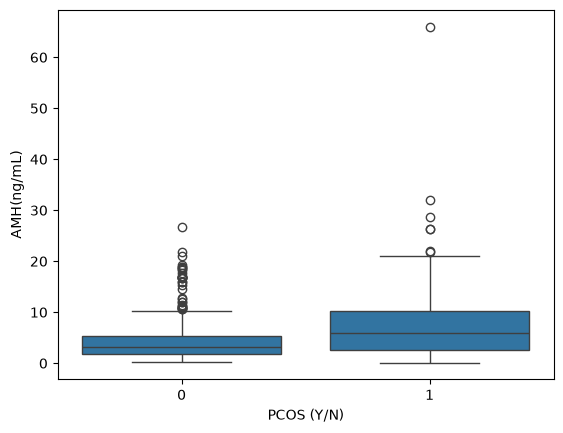

In [22]:
sns.boxplot(df,x='PCOS (Y/N)', y='AMH(ng/mL)')

In [23]:
df[(df['PCOS (Y/N)'] == 1) & (df['AMH(ng/mL)'] > 15)]

,Sl. No,Patient File No.,PCOS (Y/N),I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),AMH(ng/mL),PCOS-related Ovarian Changes
108,109,10109,1,397.08,3893.060000,16.9,True
113,114,10114,1,332.51,2.000000,21.0,True
122,123,10123,1,138.68,586.060000,17.9,True
123,124,10124,1,1.99,0.110417,19.8,True
133,134,10134,1,342.16,1.990000,19.0,True
142,143,10143,1,1.99,1.990000,18.4,True
150,151,10151,1,232.71,232.710000,15.9,True
180,181,10181,1,1.99,1.990000,32.0,True
213,214,10214,1,144.63,144.630000,26.4,True
217,218,10218,1,1.99,99.690000,22.0,True


In [24]:
df[(df['PCOS (Y/N)'] == 0) & (df['AMH(ng/mL)'] > 15)]

,Sl. No,Patient File No.,PCOS (Y/N),I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),AMH(ng/mL),PCOS-related Ovarian Changes
109,110,10110,0,926.24,600.23,17.0,True
110,111,10111,0,26290.26,3350.19,21.9,True
131,132,10132,0,1.99,1.99,19.3,True
139,140,10140,0,1.99,1.99,17.1,True
212,213,10213,0,1.99,1.99,16.9,True
231,232,10232,0,150.91,150.91,16.7,True
233,234,10234,0,392.73,1.99,16.8,True
263,264,10264,0,3.25,4.76,16.8,True
264,265,10265,0,165.61,1.99,16.9,True
268,269,10269,0,100.58,1.99,26.8,True


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

feature_cols = ['I   beta-HCG(mIU/mL)','II    beta-HCG(mIU/mL)','AMH(ng/mL)']
X= df[feature_cols]
y= df['PCOS (Y/N)']

X_train,X_test, y_train,y_test = train_test_split(X,y,test_size= 0.2, stratify=y,random_state=42)

model = LogisticRegression()
model.fit(X_train,y_train)


LogisticRegression()

In [26]:
X_train.shape
X_test.shape

(109, 3)

In [27]:
y_prediction = model.predict(X_test)
y_prediction


array([1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1])

In [28]:
from sklearn.metrics import accuracy_score, confusion_matrix
accuracy_score(y_test,y_prediction)

0.6422018348623854

In [29]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_prediction))

              precision    recall  f1-score   support

           0       0.67      0.90      0.77        73
           1       0.36      0.11      0.17        36

    accuracy                           0.64       109
   macro avg       0.52      0.51      0.47       109
weighted avg       0.57      0.64      0.57       109



In [30]:
X_train.describe()

,I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),AMH(ng/mL)
count,432.000000,432.000000,432.000000
mean,589.452884,224.404582,5.730655
std,3027.577337,1607.641325,5.991503
min,1.300000,0.110417,0.100000
25%,1.990000,1.990000,2.100000
50%,14.915000,1.990000,3.700000
75%,296.375000,75.537500,7.065000
max,30007.000000,25000.000000,66.000000


In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


model = LogisticRegression(max_iter=1000,class_weight ='balanced')
model.fit(X_train_scaled,y_train)

y_prediction = model.predict(X_test_scaled)
y_prediction

array([1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1])

In [32]:
accuracy_score(y_test,y_prediction)

0.6513761467889908

In [33]:
print(classification_report(y_test,y_prediction))

              precision    recall  f1-score   support

           0       0.72      0.78      0.75        73
           1       0.47      0.39      0.42        36

    accuracy                           0.65       109
   macro avg       0.59      0.58      0.59       109
weighted avg       0.64      0.65      0.64       109



In [34]:
from sklearn.ensemble import RandomForestClassifier

classifier = RandomForestClassifier(class_weight='balanced',random_state = 42)

classifier.fit(X_train_scaled,y_train)

y_pred = classifier.predict(X_test_scaled)

Accuracy: 63.30%
              precision    recall  f1-score   support

           0       0.71      0.77      0.74        73
           1       0.43      0.36      0.39        36

    accuracy                           0.63       109
   macro avg       0.57      0.56      0.57       109
weighted avg       0.62      0.63      0.62       109



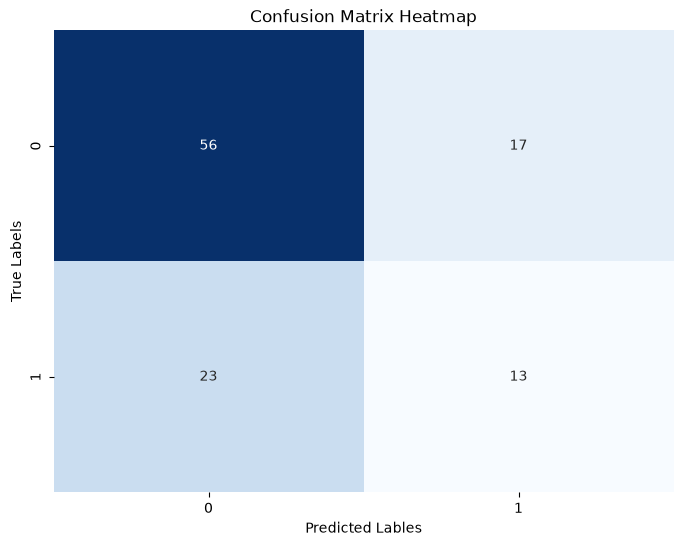

In [35]:
accuracy = accuracy_score(y_test,y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')
print(classification_report(y_test,y_pred))

conf_matrix = confusion_matrix(y_test,y_pred)

plt.figure(figsize= (8,6))
sns.heatmap(conf_matrix, annot = True, fmt='g',cmap='Blues',cbar=False)

plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Lables')
plt.ylabel('True Labels')
plt.show()

In [36]:
df_2 = pd.read_excel('PCOS_data_without_infertility.xlsx')
df_2



,Instructions to be followed :,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,NaN,NaN,NaN
1,1.0,Kindly ensure that the datas are converted to...,NaN,NaN
2,2.0,Please fill up the entire data set of a patient,NaN,NaN
3,3.0,Manipulated datas if any need to be highlighte...,NaN,NaN
4,4.0,"For every Yes/No questions *** , Indicate Yes...",NaN,NaN
5,5.0,Blood Group indications **,NaN,A+ = 11
6,NaN,NaN,NaN,A- = 12
7,NaN,NaN,NaN,B+ = 13
8,NaN,NaN,NaN,B- = 14
9,NaN,NaN,NaN,O+ =15


In [37]:
df_2.columns

Index(['Instructions to be followed :', 'Unnamed: 1', 'Unnamed: 2',
       'Unnamed: 3'],
      dtype='str')

In [38]:
df_2.dtypes

Instructions to be followed :    float64
Unnamed: 1                           str
Unnamed: 2                       float64
Unnamed: 3                           str
dtype: object

In [39]:
df_2.shape

(20, 4)

In [40]:
df_2.isnull().sum()

Instructions to be followed :     8
Unnamed: 1                        8
Unnamed: 2                       20
Unnamed: 3                       12
dtype: int64

In [41]:
import pandas as pd
xls = pd.ExcelFile('PCOS_data_without_infertility.xlsx')
xls.sheet_names

['Instructions', 'Full_new']

In [42]:
df2 = pd.read_excel('PCOS_data_without_infertility.xlsx', sheet_name='Full_new')

In [43]:
df2.shape

(541, 45)

In [44]:
df2.dtypes

Sl. No                      int64
Patient File No.            int64
PCOS (Y/N)                  int64
 Age (yrs)                  int64
Weight (Kg)               float64
Height(Cm)                float64
BMI                       float64
Blood Group                 int64
Pulse rate(bpm)             int64
RR (breaths/min)            int64
Hb(g/dl)                  float64
Cycle(R/I)                  int64
Cycle length(days)          int64
Marraige Status (Yrs)     float64
Pregnant(Y/N)               int64
No. of aborptions           int64
  I   beta-HCG(mIU/mL)    float64
II    beta-HCG(mIU/mL)     object
FSH(mIU/mL)               float64
LH(mIU/mL)                float64
FSH/LH                    float64
Hip(inch)                   int64
Waist(inch)                 int64
Waist:Hip Ratio           float64
TSH (mIU/L)               float64
AMH(ng/mL)                 object
PRL(ng/mL)                float64
Vit D3 (ng/mL)            float64
PRG(ng/mL)                float64
RBS(mg/dl)    

In [45]:
df2.columns

Index(['Sl. No', 'Patient File No.', 'PCOS (Y/N)', ' Age (yrs)', 'Weight (Kg)',
       'Height(Cm) ', 'BMI', 'Blood Group', 'Pulse rate(bpm) ',
       'RR (breaths/min)', 'Hb(g/dl)', 'Cycle(R/I)', 'Cycle length(days)',
       'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions',
       '  I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)',
       'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio',
       'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)',
       'PRG(ng/mL)', 'RBS(mg/dl)', 'Weight gain(Y/N)', 'hair growth(Y/N)',
       'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)',
       'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'BP _Systolic (mmHg)',
       'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)',
       'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)',
       'Unnamed: 44'],
      dtype='str')

In [46]:
df2['AMH(ng/mL)'] = pd.to_numeric(df2['AMH(ng/mL)'], errors = 'coerce')
df2['II    beta-HCG(mIU/mL)'] = pd.to_numeric(df2['II    beta-HCG(mIU/mL)'], errors= 'coerce')

In [47]:
df2.columns = df2.columns.str.strip()

In [48]:
df2.dtypes

Sl. No                      int64
Patient File No.            int64
PCOS (Y/N)                  int64
Age (yrs)                   int64
Weight (Kg)               float64
Height(Cm)                float64
BMI                       float64
Blood Group                 int64
Pulse rate(bpm)             int64
RR (breaths/min)            int64
Hb(g/dl)                  float64
Cycle(R/I)                  int64
Cycle length(days)          int64
Marraige Status (Yrs)     float64
Pregnant(Y/N)               int64
No. of aborptions           int64
I   beta-HCG(mIU/mL)      float64
II    beta-HCG(mIU/mL)    float64
FSH(mIU/mL)               float64
LH(mIU/mL)                float64
FSH/LH                    float64
Hip(inch)                   int64
Waist(inch)                 int64
Waist:Hip Ratio           float64
TSH (mIU/L)               float64
AMH(ng/mL)                float64
PRL(ng/mL)                float64
Vit D3 (ng/mL)            float64
PRG(ng/mL)                float64
RBS(mg/dl)    

In [49]:
df2['Unnamed: 44'].isnull().sum()

539

In [50]:
df2['Unnamed: 44'].value_counts()

Unnamed: 44
.    1
7    1
Name: count, dtype: int64

In [51]:
df2 = df2.drop(columns = ['Unnamed: 44'])

In [52]:
df2.head(5)

,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),...,Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm)
0,1,1,0,28,44.6,152.0,19.300000,15,78,22,...,0,1.0,0,110,80,3,3,18.0,18.0,8.5
1,2,2,0,36,65.0,161.5,24.921163,15,74,20,...,0,0.0,0,120,70,3,5,15.0,14.0,3.7
2,3,3,1,33,68.8,165.0,25.270891,11,72,18,...,1,1.0,0,120,80,13,15,18.0,20.0,10.0
3,4,4,0,37,65.0,148.0,29.674945,13,72,20,...,0,0.0,0,120,70,2,2,15.0,14.0,7.5
4,5,5,0,25,52.0,161.0,20.060954,11,72,18,...,0,0.0,0,120,80,3,4,16.0,14.0,7.0


In [53]:
df2.tail()

,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),...,Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm)
536,537,537,0,35,50.0,164.592,18.5,17,72,16,...,0,0.0,0,110,70,1,0,17.5,10.0,6.7
537,538,538,0,30,63.2,158.000,25.3,15,72,18,...,0,0.0,0,110,70,9,7,19.0,18.0,8.2
538,539,539,0,36,54.0,152.000,23.4,13,74,20,...,0,0.0,0,110,80,1,0,18.0,9.0,7.3
539,540,540,0,27,50.0,150.000,22.2,15,74,20,...,1,0.0,0,110,70,7,6,18.0,16.0,11.5
540,541,541,1,23,82.0,165.000,30.1,13,80,20,...,1,1.0,0,120,70,9,10,19.0,18.0,6.9


In [54]:
df2.isnull().sum()

Sl. No                    0
Patient File No.          0
PCOS (Y/N)                0
Age (yrs)                 0
Weight (Kg)               0
Height(Cm)                0
BMI                       0
Blood Group               0
Pulse rate(bpm)           0
RR (breaths/min)          0
Hb(g/dl)                  0
Cycle(R/I)                0
Cycle length(days)        0
Marraige Status (Yrs)     1
Pregnant(Y/N)             0
No. of aborptions         0
I   beta-HCG(mIU/mL)      0
II    beta-HCG(mIU/mL)    1
FSH(mIU/mL)               0
LH(mIU/mL)                0
FSH/LH                    0
Hip(inch)                 0
Waist(inch)               0
Waist:Hip Ratio           0
TSH (mIU/L)               0
AMH(ng/mL)                1
PRL(ng/mL)                0
Vit D3 (ng/mL)            0
PRG(ng/mL)                0
RBS(mg/dl)                0
Weight gain(Y/N)          0
hair growth(Y/N)          0
Skin darkening (Y/N)      0
Hair loss(Y/N)            0
Pimples(Y/N)              0
Fast food (Y/N)     

In [55]:
df2[['AMH(ng/mL)', 'II    beta-HCG(mIU/mL)']].dtypes

AMH(ng/mL)                float64
II    beta-HCG(mIU/mL)    float64
dtype: object

In [56]:
df2[['AMH(ng/mL)', 'II    beta-HCG(mIU/mL)']].isnull().sum()

AMH(ng/mL)                1
II    beta-HCG(mIU/mL)    1
dtype: int64

In [57]:
df2[df2['AMH(ng/mL)'].isnull()]

,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),...,Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm)
305,306,306,0,37,56.0,152.0,24.238227,13,74,20,...,1,0.0,1,120,70,4,5,17.0,16.0,5.6


In [58]:
df2[df2['II    beta-HCG(mIU/mL)'].isnull()]

,Sl. No,Patient File No.,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),...,Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm)
123,124,124,1,23,40.0,150.0,17.777778,15,74,18,...,0,1.0,1,100,70,10,13,18.0,17.0,12.5


In [59]:
df2['AMH(ng/mL)'] = df2['AMH(ng/mL)'].fillna(df2['AMH(ng/mL)'].mean())

df2['II    beta-HCG(mIU/mL)'] = df2['II    beta-HCG(mIU/mL)'].fillna(df2['II    beta-HCG(mIU/mL)'].mean())

In [60]:
df2[['AMH(ng/mL)', 'II    beta-HCG(mIU/mL)']].isnull().sum()

AMH(ng/mL)                0
II    beta-HCG(mIU/mL)    0
dtype: int64

In [61]:
set(df.columns) - set(df2.columns)

{'PCOS-related Ovarian Changes'}

In [62]:
(df['Patient File No.'].values == df2['Patient File No.'].values).all()

False

In [63]:
mismatch = df['Patient File No.'].values != df2['Patient File No.'].values
df[mismatch]['Patient File No.']

0      10001
1      10002
2      10003
3      10004
4      10005
       ...  
536    10537
537    10538
538    10539
539    10540
540    10541
Name: Patient File No., Length: 541, dtype: int64

In [64]:
df2[mismatch]['Patient File No.']

0        1
1        2
2        3
3        4
4        5
      ... 
536    537
537    538
538    539
539    540
540    541
Name: Patient File No., Length: 541, dtype: int64

In [65]:
(df['Patient File No.'].values == df2['Patient File No.'].values + 10000).all()

True

In [66]:
(df['PCOS (Y/N)'].values == df2['PCOS (Y/N)'].values).all()

True

In [67]:
df2.columns

Index(['Sl. No', 'Patient File No.', 'PCOS (Y/N)', 'Age (yrs)', 'Weight (Kg)',
       'Height(Cm)', 'BMI', 'Blood Group', 'Pulse rate(bpm)',
       'RR (breaths/min)', 'Hb(g/dl)', 'Cycle(R/I)', 'Cycle length(days)',
       'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions',
       'I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)',
       'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio',
       'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)',
       'PRG(ng/mL)', 'RBS(mg/dl)', 'Weight gain(Y/N)', 'hair growth(Y/N)',
       'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)',
       'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'BP _Systolic (mmHg)',
       'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)',
       'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)'],
      dtype='str')

In [68]:
df2_group = df2.groupby('PCOS (Y/N)')
df2_group.mean()

,Sl. No,Patient File No.,Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),...,Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm)
PCOS (Y/N),,,,,,,,,,,,,,,,,,,,,
0,264.357143,264.357143,32.065934,58.008791,156.197934,23.747397,13.755495,72.964286,19.200549,11.107390,...,0.390110,0.382920,0.228022,114.620879,76.780220,4.351648,4.637363,14.687637,15.225824,8.315027
1,284.661017,284.661017,30.124294,62.985876,157.074847,25.470919,13.898305,73.830508,19.333333,11.268305,...,0.694915,0.785311,0.288136,114.745763,77.231638,9.785311,10.762712,15.697740,15.916215,8.806780


In [69]:
df2.groupby('PCOS (Y/N)')[['I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)','AMH(ng/mL)']].mean()

,I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),AMH(ng/mL)
PCOS (Y/N),,,
0,728.982437,223.975137,4.544470
1,532.042537,268.891409,7.844633


In [70]:
cause_features = ['BMI','Blood Group','Pulse rate(bpm)',
       'RR (breaths/min)', 'Hb(g/dl)','Cycle(R/I)', 'Cycle length(days)','Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions',
       'I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)',
       'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio',
       'TSH (mIU/L)', 'AMH(ng/mL)','Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)']

In [71]:
df2.groupby('PCOS (Y/N)')[cause_features].mean()

,BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),Cycle(R/I),Cycle length(days),Marraige Status (Yrs),Pregnant(Y/N),No. of aborptions,...,LH(mIU/mL),FSH/LH,Hip(inch),Waist(inch),Waist:Hip Ratio,TSH (mIU/L),AMH(ng/mL),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm)
PCOS (Y/N),,,,,,,,,,,,,,,,,,,,,
0,23.747397,13.755495,72.964286,19.200549,11.107390,2.307692,5.126374,8.057692,0.390110,0.315934,...,2.612676,7.680132,37.543956,33.428571,0.891495,3.007810,4.544470,14.687637,15.225824,8.315027
1,25.470919,13.898305,73.830508,19.333333,11.268305,3.079096,4.559322,6.901705,0.361582,0.231638,...,14.402328,5.310427,38.915254,34.689266,0.892717,2.926723,7.844633,15.697740,15.916215,8.806780


In [72]:
df2.groupby('PCOS (Y/N)')[cause_features].std()

,BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),Cycle(R/I),Cycle length(days),Marraige Status (Yrs),Pregnant(Y/N),No. of aborptions,...,LH(mIU/mL),FSH/LH,Hip(inch),Waist(inch),Waist:Hip Ratio,TSH (mIU/L),AMH(ng/mL),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm)
PCOS (Y/N),,,,,,,,,,,,,,,,,,,,,
0,3.759378,1.823658,5.033370,1.709123,0.880353,0.722596,1.264243,4.815977,0.488446,0.750881,...,2.103597,71.931510,3.779857,3.446219,0.046330,4.136968,4.285040,3.869772,3.406305,2.258606
1,4.396117,1.877150,2.731254,1.646852,0.830547,1.008184,1.821006,4.696862,0.481822,0.551356,...,151.478646,25.023422,4.191258,3.758256,0.046438,2.823221,7.791138,2.730904,3.088971,1.923866


In [73]:
means = df2.groupby('PCOS (Y/N)')[df2.select_dtypes('number').columns].mean()
gap = (means.loc[1] - means.loc[0]).abs()
pooled_std = df2.select_dtypes('number').std()
effect_size = (gap / pooled_std).sort_values(ascending = False)
effect_size



PCOS (Y/N)                2.129405
Follicle No. (R)          1.380550
Follicle No. (L)          1.284768
Skin darkening (Y/N)      1.013028
hair growth(Y/N)          0.989463
Weight gain(Y/N)          0.939168
Cycle(R/I)                0.855262
Fast food (Y/N)           0.804389
Pimples(Y/N)              0.609173
AMH(ng/mL)                0.561619
Weight (Kg)               0.451302
BMI                       0.424890
Cycle length(days)        0.380056
Hair loss(Y/N)            0.368128
Age (yrs)                 0.358832
Waist(inch)               0.350495
Hip(inch)                 0.345596
Avg. F size (L) (mm)      0.283193
Marraige Status (Yrs)     0.240639
Endometrium (mm)          0.227097
Avg. F size (R) (mm)      0.208021
Pulse rate(bpm)           0.195523
Hb(g/dl)                  0.185620
Vit D3 (ng/mL)            0.182052
Height(Cm)                0.145340
Reg.Exercise(Y/N)         0.139129
LH(mIU/mL)                0.136024
Sl. No                    0.129889
Patient File No.    

In [74]:
effect_size[['LH(mIU/mL)', 'FSH(mIU/mL)', 'FSH/LH']]

LH(mIU/mL)     0.136024
FSH(mIU/mL)    0.064562
FSH/LH         0.039045
dtype: float64

In [75]:
df2.columns

Index(['Sl. No', 'Patient File No.', 'PCOS (Y/N)', 'Age (yrs)', 'Weight (Kg)',
       'Height(Cm)', 'BMI', 'Blood Group', 'Pulse rate(bpm)',
       'RR (breaths/min)', 'Hb(g/dl)', 'Cycle(R/I)', 'Cycle length(days)',
       'Marraige Status (Yrs)', 'Pregnant(Y/N)', 'No. of aborptions',
       'I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 'FSH(mIU/mL)',
       'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio',
       'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 'Vit D3 (ng/mL)',
       'PRG(ng/mL)', 'RBS(mg/dl)', 'Weight gain(Y/N)', 'hair growth(Y/N)',
       'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)',
       'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'BP _Systolic (mmHg)',
       'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)',
       'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)'],
      dtype='str')

In [76]:
df2.isnull().sum()

Sl. No                    0
Patient File No.          0
PCOS (Y/N)                0
Age (yrs)                 0
Weight (Kg)               0
Height(Cm)                0
BMI                       0
Blood Group               0
Pulse rate(bpm)           0
RR (breaths/min)          0
Hb(g/dl)                  0
Cycle(R/I)                0
Cycle length(days)        0
Marraige Status (Yrs)     1
Pregnant(Y/N)             0
No. of aborptions         0
I   beta-HCG(mIU/mL)      0
II    beta-HCG(mIU/mL)    0
FSH(mIU/mL)               0
LH(mIU/mL)                0
FSH/LH                    0
Hip(inch)                 0
Waist(inch)               0
Waist:Hip Ratio           0
TSH (mIU/L)               0
AMH(ng/mL)                0
PRL(ng/mL)                0
Vit D3 (ng/mL)            0
PRG(ng/mL)                0
RBS(mg/dl)                0
Weight gain(Y/N)          0
hair growth(Y/N)          0
Skin darkening (Y/N)      0
Hair loss(Y/N)            0
Pimples(Y/N)              0
Fast food (Y/N)     

In [77]:
df2['Fast food (Y/N)'] = df2['Fast food (Y/N)'].fillna(df2['Fast food (Y/N)'].mode()[0])

Training Logistic Regression Model

In [78]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

features = [
     'Cycle(R/I)','Weight (Kg)','Cycle length(days)','Follicle No. (L)', 'Follicle No. (R)','Skin darkening (Y/N)', 'Hair loss(Y/N)',
       'Fast food (Y/N)','Pimples(Y/N)','AMH(ng/mL)','Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)','Weight gain(Y/N)', 'hair growth(Y/N)']

X= df2[features]
y= df2['PCOS (Y/N)']

X_train, X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state=42,stratify = y)



In [79]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report,confusion_matrix, accuracy_score


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model.fit(X_train_scaled,y_train)

y_prediction = model.predict(X_test_scaled)

print(f'Accuracy score of model is : {accuracy_score(y_test,y_prediction)}')
print(f'Classification Report is : {classification_report(y_test,y_prediction)}')
print(confusion_matrix(y_test,y_prediction))


Accuracy score of model is : 0.908256880733945
Classification Report is :               precision    recall  f1-score   support

           0       0.94      0.92      0.93        73
           1       0.84      0.89      0.86        36

    accuracy                           0.91       109
   macro avg       0.89      0.90      0.90       109
weighted avg       0.91      0.91      0.91       109

[[67  6]
 [ 4 32]]


Training Random Forest Model

In [80]:
from sklearn.ensemble import RandomForestClassifier

classifier = RandomForestClassifier(class_weight = 'balanced',random_state = 42)

classifier.fit(X_train_scaled,y_train)

y_pred = classifier.predict(X_test_scaled)


Accuracy: 92.66%
              precision    recall  f1-score   support

           0       0.92      0.97      0.95        73
           1       0.94      0.83      0.88        36

    accuracy                           0.93       109
   macro avg       0.93      0.90      0.91       109
weighted avg       0.93      0.93      0.93       109



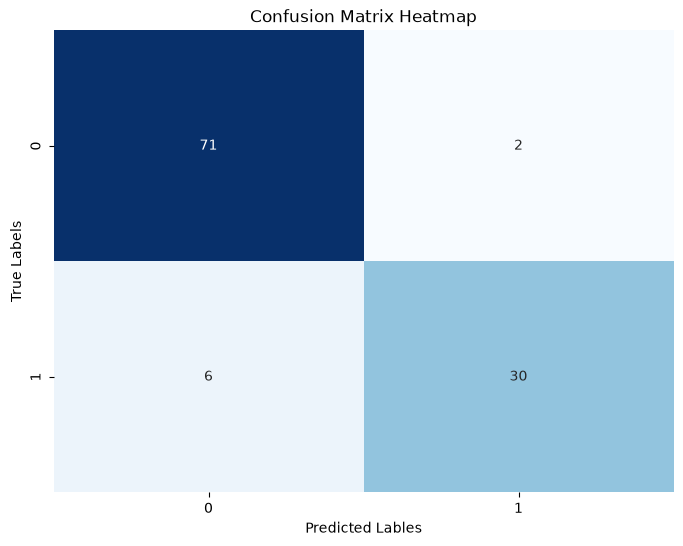

In [81]:
accuracy = accuracy_score(y_test,y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')
print(classification_report(y_test,y_pred))

conf_matrix = confusion_matrix(y_test,y_pred)

plt.figure(figsize= (8,6))
sns.heatmap(conf_matrix, annot = True, fmt='g',cmap='Blues',cbar=False)

plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Lables')
plt.ylabel('True Labels')
plt.show()

In [82]:
df2[cause_features].isnull().sum()

for col in cause_features:
    if df2[col].isnull().any():
        if df2[col].dtype == 'object':
            df2[col] = df2[col].fillna(df2[col].mode()[0])
        else:
            df2[col] = df2[col].fillna(df2[col].median())



In [83]:
X2 = df2[cause_features]
y2 = df2['PCOS (Y/N)']

X2_train, X2_test, y2_train, y2_test = train_test_split(X2,y2,test_size=0.2,stratify=y2,random_state=42)


In [84]:

scaler2= StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)


=== Random Forest — Full Clinical Features (23) ===
Accuracy: 71.56%
              precision    recall  f1-score   support

           0       0.74      0.89      0.81        73
           1       0.62      0.36      0.46        36

    accuracy                           0.72       109
   macro avg       0.68      0.63      0.63       109
weighted avg       0.70      0.72      0.69       109



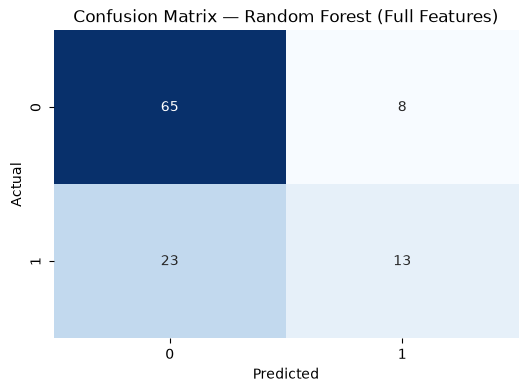

In [85]:
rf2 = RandomForestClassifier(class_weight = 'balanced', random_state=42)
rf2.fit(X2_train_scaled,y2_train)
y2_pred = rf2.predict(X2_test_scaled)

print("=== Random Forest — Full Clinical Features (23) ===")
print(f"Accuracy: {accuracy_score(y2_test, y2_pred)*100:.2f}%")
print(classification_report(y2_test, y2_pred))


conf2 = confusion_matrix(y2_test, y2_pred)
plt.figure(figsize=(6,4))
sns.heatmap(conf2, annot=True, fmt='g', cmap='Blues', cbar=False)
plt.title('Confusion Matrix — Random Forest (Full Features)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

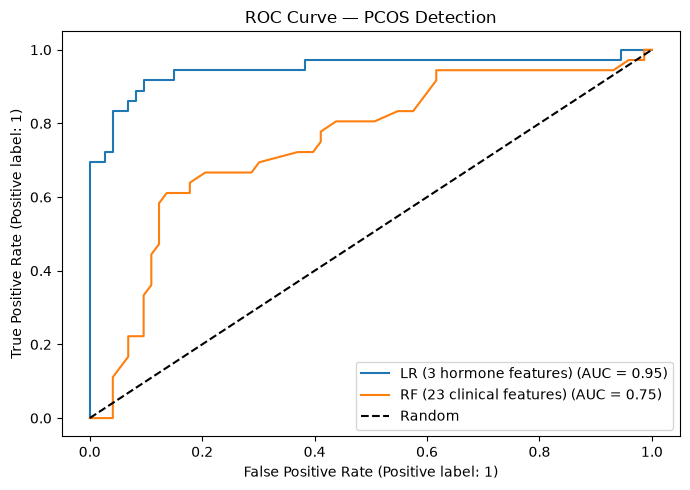

In [91]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7, 5))
RocCurveDisplay.from_estimator(model, X_test_scaled, y_test,
                                name="LR (3 hormone features)", ax=ax)
RocCurveDisplay.from_estimator(rf2, X2_test_scaled, y2_test,
                                name="RF (23 clinical features)", ax=ax)
ax.plot([0,1],[0,1],'k--', label='Random')
ax.set_title('ROC Curve — PCOS Detection')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
import shap
import numpy as np

explainer = shap.TreeExplainer(rf2)
shap_values = explainer.shap_values(X2_test_scaled)


print(type(shap_values))
print(np.array(shap_values).shape)

<class 'numpy.ndarray'>
(109, 23, 2)


shap_values shape: (109, 23, 2)
X2_test_scaled shape: (109, 23)
cause_features count: 23


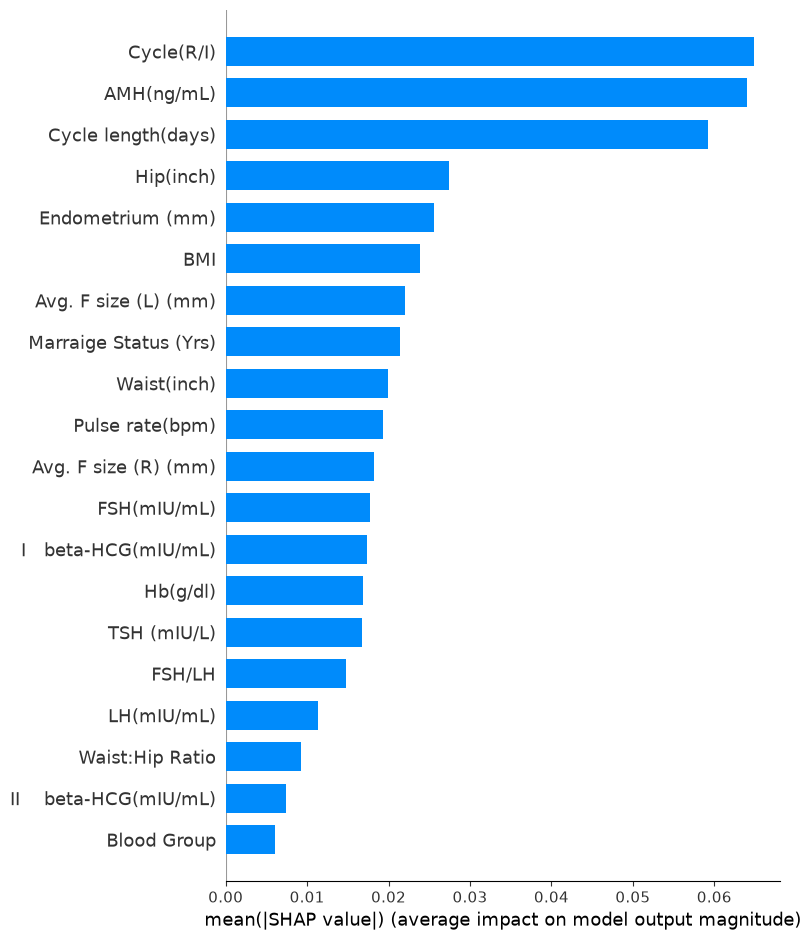

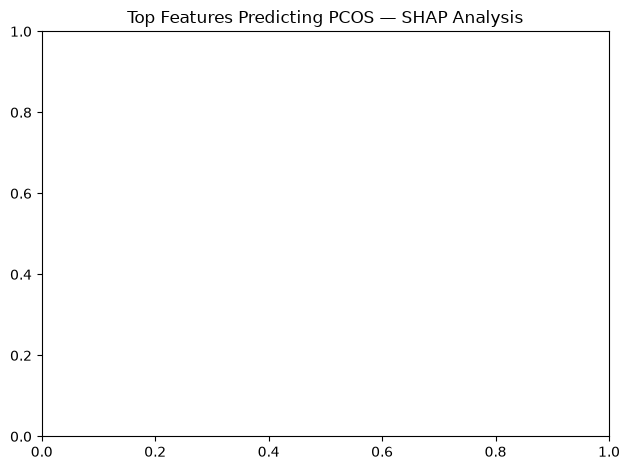

In [102]:
# shap.summary_plot(shap_values[1], X2_test_scaled,
#                   feature_names=cause_features,
#                   plot_type="bar", show=True)
# plt.title("Top features Predicting PCOS - SHAP Analysis")
import matplotlib.pyplot as plt
import shap
import numpy as np

print("shap_values shape:", np.array(shap_values).shape)
print("X2_test_scaled shape:", X2_test_scaled.shape)
print("cause_features count:", len(cause_features))

# Force a fresh figure
plt.close('all')
fig = plt.figure(figsize=(10, 8))

shap.summary_plot(shap_values[:, :, 1],
                  X2_test_scaled,
                  feature_names=cause_features,
                  plot_type="bar",
                  show=True)

plt.title("Top Features Predicting PCOS — SHAP Analysis")
plt.tight_layout()